# Ejemplo 2 — Visualización alineada de deformaciones y tensiones

Este cuaderno valida el **visualizador base** de estados seccionales:

- gira la sección para dejar la **línea neutra horizontal**;
- alinea la planta, el diagrama de deformaciones y los diagramas de tensiones
  sobre la misma cota vertical `v`;
- representa todos los materiales y distingue los cordones enfundados;
- conserva la evolución completa por fases.

La visualización es una **proyección de un cálculo ya resuelto**. No vuelve a
resolver el equilibrio ni contiene lógica normativa.

```text
ModeloEstructural + HistorialSeccion + proveedor de leyes
                         │
                         ▼
       construir_evolucion_alineada(...)
                         │
                         ▼
            EvolucionAlineadaVista (DTO)
                         │
              ┌──────────┼──────────┐
              ▼          ▼          ▼
           PySide      Web       Notebook
```

## 1. Separación de responsabilidades

| Capa | Responsabilidad en esta prueba |
|---|---|
| `domain/mechanics/alineacion_deformaciones.py` | Rotación mecánica y definición de la línea neutra |
| `domain/mechanics/campo_tensiones.py` | Deformación constitutiva y tensión en una fibra |
| `application/use_cases/visualizar_tensiones.py` | Geometría efectiva, perfiles y DTO portable |
| Este cuaderno | Dibujo con Matplotlib, sustituible por cualquier otra UI |

El contrato de salida contiene mm, tanto por uno y MPa. No contiene píxeles,
colores, objetos Qt ni coordenadas de pantalla.

In [1]:
from __future__ import annotations

import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from placas_alveolares.application.dtos.visualizacion_tensiones import (
    AdherenciaVista,
    ComponenteVista,
    FaseAlineadaVista,
    TipoMaterialVista,
)
from placas_alveolares.application.use_cases.visualizar_tensiones import (
    construir_evolucion_alineada,
)
from placas_alveolares.domain.mechanics.analisis_fases import analizar_fases
from placas_alveolares.domain.mechanics.proveedor_leyes_elasticas import (
    ProveedorLeyesElasticas,
)
from placas_alveolares.domain.model.acciones import EsfuerzosInternos
from placas_alveolares.domain.model.fases import Fase
from placas_alveolares.domain.model.geometria import Punto, circulo, rectangulo
from placas_alveolares.domain.model.materiales import (
    AceroArmadura,
    AceroPretensado,
    Hormigon,
)
from placas_alveolares.domain.model.modelo import ModeloEstructural
from placas_alveolares.domain.model.operaciones import (
    PerdidaPorTension,
    PretensadoPorTension,
)
from placas_alveolares.domain.model.seccion import (
    ComponenteSeccion,
    CondicionAdherencia,
    Seccion,
)
from placas_alveolares.domain.model.tiempo import Tiempo
from placas_alveolares.domain.numerics import Newton, OpcionesNewton
from placas_alveolares.domain.state.operaciones import (
    AdherirComponente,
    AplicarPerdidaPretensado,
    AsignarPretensado,
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.20,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

## 2. Sección de prueba

La sección mezcla deliberadamente tres materiales:

- hormigón;
- cuatro barras pasivas, que entran en servicio en la fase 2;
- tres cordones de pretensado, inicialmente enfundados.

Los cordones declaran al hormigón como anfitrión, por lo que la malla efectiva
del hormigón descuenta sus huecos. La rótula biaxial de la fase de servicio hará
que la línea neutra no sea horizontal en los ejes originales.

In [2]:
ANCHO = 500.0
ALTO = 700.0
HORMIGON = Hormigon(fck=40.0, fcm=48.0, ecm=35_000.0)
ACERO_PASIVO = AceroArmadura(
    fyk=500.0,
    ftk=550.0,
    es=200_000.0,
    eps_uk=0.05,
)
ACERO_PRETENSADO = AceroPretensado(fpk=1_860.0, ep=195_000.0)

COMPONENTES = (
    ComponenteSeccion(
        id="hormigon",
        geometria=rectangulo(ANCHO, ALTO, z_base=-ALTO / 2.0),
        material=HORMIGON,
    ),
    ComponenteSeccion(
        id="pasivo-sup-izq",
        geometria=circulo(Punto(y=-180.0, z=300.0), radio=10.0),
        material=ACERO_PASIVO,
        fase_incorporacion=2,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="pasivo-sup-der",
        geometria=circulo(Punto(y=180.0, z=300.0), radio=10.0),
        material=ACERO_PASIVO,
        fase_incorporacion=2,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="pasivo-inf-izq",
        geometria=circulo(Punto(y=-180.0, z=-300.0), radio=10.0),
        material=ACERO_PASIVO,
        fase_incorporacion=2,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="pasivo-inf-der",
        geometria=circulo(Punto(y=180.0, z=-300.0), radio=10.0),
        material=ACERO_PASIVO,
        fase_incorporacion=2,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="tendon-izq",
        geometria=circulo(Punto(y=-140.0, z=-250.0), radio=15.0),
        material=ACERO_PRETENSADO,
        adherencia=CondicionAdherencia.ENFUNDADO,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="tendon-centro",
        geometria=circulo(Punto(y=0.0, z=-250.0), radio=15.0),
        material=ACERO_PRETENSADO,
        adherencia=CondicionAdherencia.ENFUNDADO,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="tendon-der",
        geometria=circulo(Punto(y=140.0, z=-250.0), radio=15.0),
        material=ACERO_PRETENSADO,
        adherencia=CondicionAdherencia.ENFUNDADO,
        componente_anfitrion_id="hormigon",
    ),
)

## 3. Fases y cálculo

La secuencia es:

1. **Tesado inicial**: los cordones reciben deformación impuesta, pero siguen
   enfundados y no contribuyen al equilibrio.
2. **Transferencia**: se aplica una pérdida, se adhieren los cordones y se
   resuelve equilibrio con flexión biaxial.
3. **Servicio**: entran las armaduras pasivas y se incrementan las acciones.

El proveedor es elástico para mantener el ejemplo simple. La visualización
funciona igual con leyes normativas inyectadas.

In [3]:
TENDONES = ("tendon-izq", "tendon-centro", "tendon-der")
MODELO = ModeloEstructural(
    seccion=Seccion(componentes=COMPONENTES),
    fases=(
        Fase(
            indice=0,
            tiempo_inicio=Tiempo(0.0),
            tiempo_fin=Tiempo(0.0),
            resolver_equilibrio=False,
            operaciones=tuple(
                AsignarPretensado(
                    tendon,
                    PretensadoPorTension(1_250.0),
                )
                for tendon in TENDONES
            ),
            nombre="Tesado inicial",
        ),
        Fase(
            indice=1,
            tiempo_inicio=Tiempo(0.0),
            tiempo_fin=Tiempo(1.0),
            acciones=EsfuerzosInternos(m_y=80.0e6, m_z=20.0e6),
            operaciones=tuple(
                operacion
                for tendon in TENDONES
                for operacion in (
                    AplicarPerdidaPretensado(
                        tendon,
                        PerdidaPorTension(60.0),
                    ),
                    AdherirComponente(tendon),
                )
            ),
            nombre="Transferencia",
        ),
        Fase(
            indice=2,
            tiempo_inicio=Tiempo(1.0),
            tiempo_fin=Tiempo(90.0),
            acciones=EsfuerzosInternos(m_y=300.0e6, m_z=100.0e6),
            nombre="Servicio",
        ),
    ),
    fase_activa=1,
)

PROVEEDOR = ProveedorLeyesElasticas()
SOLVER = Newton(
    OpcionesNewton(
        tolerancia_residuo=1.0e-9,
        tolerancia_residuo_relativa=1.0e-9,
        max_iteraciones=100,
    )
)
HISTORIAL = analizar_fases(MODELO, PROVEEDOR, SOLVER)
EVOLUCION = construir_evolucion_alineada(
    MODELO,
    HISTORIAL,
    PROVEEDOR,
    muestras_perfil=241,
)

print(f"Fases calculadas: {len(EVOLUCION.fases)}")
print(f"Unidades: {EVOLUCION.unidad_longitud}, {EVOLUCION.unidad_tension}")
for fase in EVOLUCION.fases:
    estado = "equilibrada" if fase.equilibrio_resuelto else "sin equilibrio"
    print(
        f"  Fase {fase.indice}: {fase.nombre:<16} "
        f"t={fase.tiempo_fin_dias:>5.1f} d  {estado:<15} "
        f"giro={math.degrees(fase.angulo_radianes):>6.2f}°  "
        f"σ=[{fase.limites.tension.minimo:>9.2f}, "
        f"{fase.limites.tension.maximo:>9.2f}] MPa"
    )

Fases calculadas: 3
Unidades: mm, MPa
  Fase 0: Tesado inicial   t=  0.0 d  sin equilibrio  giro=  0.00°  σ=[     0.00,   1250.00] MPa
  Fase 1: Transferencia    t=  1.0 d  equilibrada     giro=  3.38°  σ=[   -22.50,   1095.86] MPa
  Fase 2: Servicio         t= 90.0 d  equilibrada     giro= 12.38°  σ=[   -36.41,   1085.37] MPa


## 4. Cómo se alinea la línea neutra

Para el plano común

$$\varepsilon(y,z)=\varepsilon_0+\kappa_y z-\kappa_z y,$$

la curvatura resultante es $\kappa=\sqrt{\kappa_y^2+\kappa_z^2}$. El sistema
girado se define con:

$$u=\frac{\kappa_y y+\kappa_z z}{\kappa}, \qquad
q=\frac{-\kappa_z y+\kappa_y z}{\kappa}.$$

Trasladando el origen a la línea neutra, $v=q+\varepsilon_0/\kappa$, resulta

$$\boxed{\varepsilon=\kappa\,v}.$$

Por tanto la línea neutra queda en $v=0$ y los tres paneles pueden compartir la
misma escala vertical. Si $\kappa\approx 0$ no existe dirección única de línea
neutra: se conserva la orientación original y el DTO lo indica con
`linea_neutra_definida = False`.

Cada componente se muestrea en la vertical que pasa por el centroide de su
geometría efectiva. Los huecos interrumpen el perfil en tramos, de modo que no
se dibuja tensión dentro de un alveolo o de un cordón embebido.

## 5. Utilidades de dibujo

El DTO no impone ninguna estética. Estas funciones son el **adaptador de
presentación** del cuaderno y podrían sustituirse por un widget Qt, un canvas
web o un exportador SVG sin tocar el núcleo.

In [4]:
COLORES = {
    TipoMaterialVista.HORMIGON: "#cfcfcf",
    TipoMaterialVista.ACERO_ARMADURA: "#d97706",
    TipoMaterialVista.ACERO_PRETENSADO: "#2563eb",
}
BORDES = {
    TipoMaterialVista.HORMIGON: "#4b5563",
    TipoMaterialVista.ACERO_ARMADURA: "#92400e",
    TipoMaterialVista.ACERO_PRETENSADO: "#1e3a8a",
}
ETIQUETAS = {
    TipoMaterialVista.HORMIGON: "Hormigón",
    TipoMaterialVista.ACERO_ARMADURA: "Acero pasivo",
    TipoMaterialVista.ACERO_PRETENSADO: "Pretensado",
}


def color_componente(componente: ComponenteVista) -> str:
    """Color de relleno; aclara los cordones enfundados."""
    if componente.adherencia is AdherenciaVista.ENFUNDADO:
        return "#93c5fd"
    return COLORES[componente.tipo_material]


def dibujar_seccion(ax: plt.Axes, fase: FaseAlinearVista) -> None:
    """Dibuja la planta girada con sus huecos y materiales."""
    for componente in fase.componentes:
        zorder = (
            3
            if componente.tipo_material is not TipoMaterialVista.HORMIGON
            else 2
        )
        ax.add_patch(
            Polygon(
                [(p.u, p.v) for p in componente.geometria.exterior.puntos],
                closed=True,
                facecolor=color_componente(componente),
                edgecolor=BORDES[componente.tipo_material],
                linewidth=0.8,
                zorder=zorder,
            )
        )
        for hueco in componente.geometria.huecos:
            ax.add_patch(
                Polygon(
                    [(p.u, p.v) for p in hueco.puntos],
                    closed=True,
                    facecolor="white",
                    edgecolor="white",
                    linewidth=0.5,
                    zorder=2.5,
                )
            )
    ax.set_aspect("equal")
    ax.set_xlabel("u (mm)")


def dibujar_deformaciones(ax: plt.Axes, fase: FaseAlinearVista) -> None:
    """Dibuja el plano común y las deformaciones con relleno translúcido."""
    muestra_a, muestra_b = fase.deformacion_comun
    x_comun = [
        muestra_a.deformacion * 1000.0,
        muestra_b.deformacion * 1000.0,
    ]
    y_comun = [muestra_a.v, muestra_b.v]
    ax.fill_betweenx(
        y_comun,
        0.0,
        x_comun,
        color="#111827",
        alpha=0.10,
        linewidth=0.0,
        zorder=1,
    )
    ax.plot(
        x_comun,
        y_comun,
        color="#111827",
        linewidth=2.2,
        label="Plano común",
        zorder=2,
    )
    for componente in fase.componentes:
        for tramo in componente.perfil.tramos:
            x = [m.deformacion * 1000.0 for m in tramo.muestras]
            y = [m.v for m in tramo.muestras]
            ax.fill_betweenx(
                y,
                0.0,
                x,
                color=COLORES[componente.tipo_material],
                alpha=0.16,
                linewidth=0.0,
                zorder=1,
            )
            ax.plot(
                x,
                y,
                color=COLORES[componente.tipo_material],
                linewidth=1.0,
                linestyle="--",
                alpha=0.85,
                zorder=2,
            )
    ax.axvline(0.0, color="0.3", linewidth=0.8)
    ax.set_xlabel("ε (‰)")


def dibujar_tensiones(
    ax: plt.Axes,
    fase: FaseAlinearVista,
    tipos: tuple[TipoMaterialVista, ...] | None = None,
    *,
    etiquetar: bool = False,
) -> None:
    """Dibuja perfiles de tensión con área translúcida hasta el eje cero."""
    for componente in fase.componentes:
        if tipos is not None and componente.tipo_material not in tipos:
            continue
        for tramo in componente.perfil.tramos:
            x = [m.tension for m in tramo.muestras]
            y = [m.v for m in tramo.muestras]
            ax.fill_betweenx(
                y,
                0.0,
                x,
                color=COLORES[componente.tipo_material],
                alpha=0.22,
                linewidth=0.0,
                zorder=1,
            )
            ax.plot(
                x,
                y,
                color=COLORES[componente.tipo_material],
                linewidth=1.7,
                linestyle=(
                    "--"
                    if componente.adherencia is AdherenciaVista.ENFUNDADO
                    else "-"
                ),
                label=componente.componente_id if etiquetar else None,
                zorder=2,
            )
    ax.axvline(0.0, color="0.3", linewidth=0.8)
    ax.set_xlabel("σ (MPa)")


def limites_verticales() -> tuple[float, float]:
    """Rango vertical común de todas las fases, con margen."""
    rango = EVOLUCION.limites_globales.vertical
    margen = 0.04 * rango.amplitud
    return rango.minimo - margen, rango.maximo + margen


def limite_horizontal(rango) -> float:
    """Semiamplitud simétrica para comparar magnitudes entre fases."""
    return max(abs(rango.minimo), abs(rango.maximo), 1.0e-12) * 1.15


def limite_tensiones(
    tipos: tuple[TipoMaterialVista, ...],
) -> float:
    """Escala común de un grupo de materiales a lo largo de todas las fases."""
    valores = [
        muestra.tension
        for fase in EVOLUCION.fases
        for componente in fase.componentes
        if componente.tipo_material in tipos
        for tramo in componente.perfil.tramos
        for muestra in tramo.muestras
    ]
    limite = max((abs(valor) for valor in valores), default=1.0)
    return limite * 1.15


Y_LIM = limites_verticales()
EPS_LIM = limite_horizontal(EVOLUCION.limites_globales.deformacion) * 1000.0
SIGMA_LIM_HORMIGON = limite_tensiones((TipoMaterialVista.HORMIGON,))
SIGMA_LIM_PASIVO = limite_tensiones((TipoMaterialVista.ACERO_ARMADURA,))
SIGMA_LIM_ACTIVO = limite_tensiones((TipoMaterialVista.ACERO_PRETENSADO,))

## 6. Evolución completa

Cada fila es una fase y todas las columnas comparten la cota `v`. La línea
neutra se dibuja en `v = 0` cuando existe. Los perfiles discontinuos
corresponden a componentes **enfundados**: se muestra su tensión propia, pero
no contribuyen al equilibrio de la sección.

Hormigón, acero pasivo y pretensado tienen **escalas independientes**. Si se
compartiera una única escala, los aproximadamente 1 100 MPa del pretensado
dejarían invisible la respuesta del hormigón y del acero pasivo. Las áreas se
rellenan con transparencia hasta el eje cero para leer la forma del diagrama,
no solo su contorno.

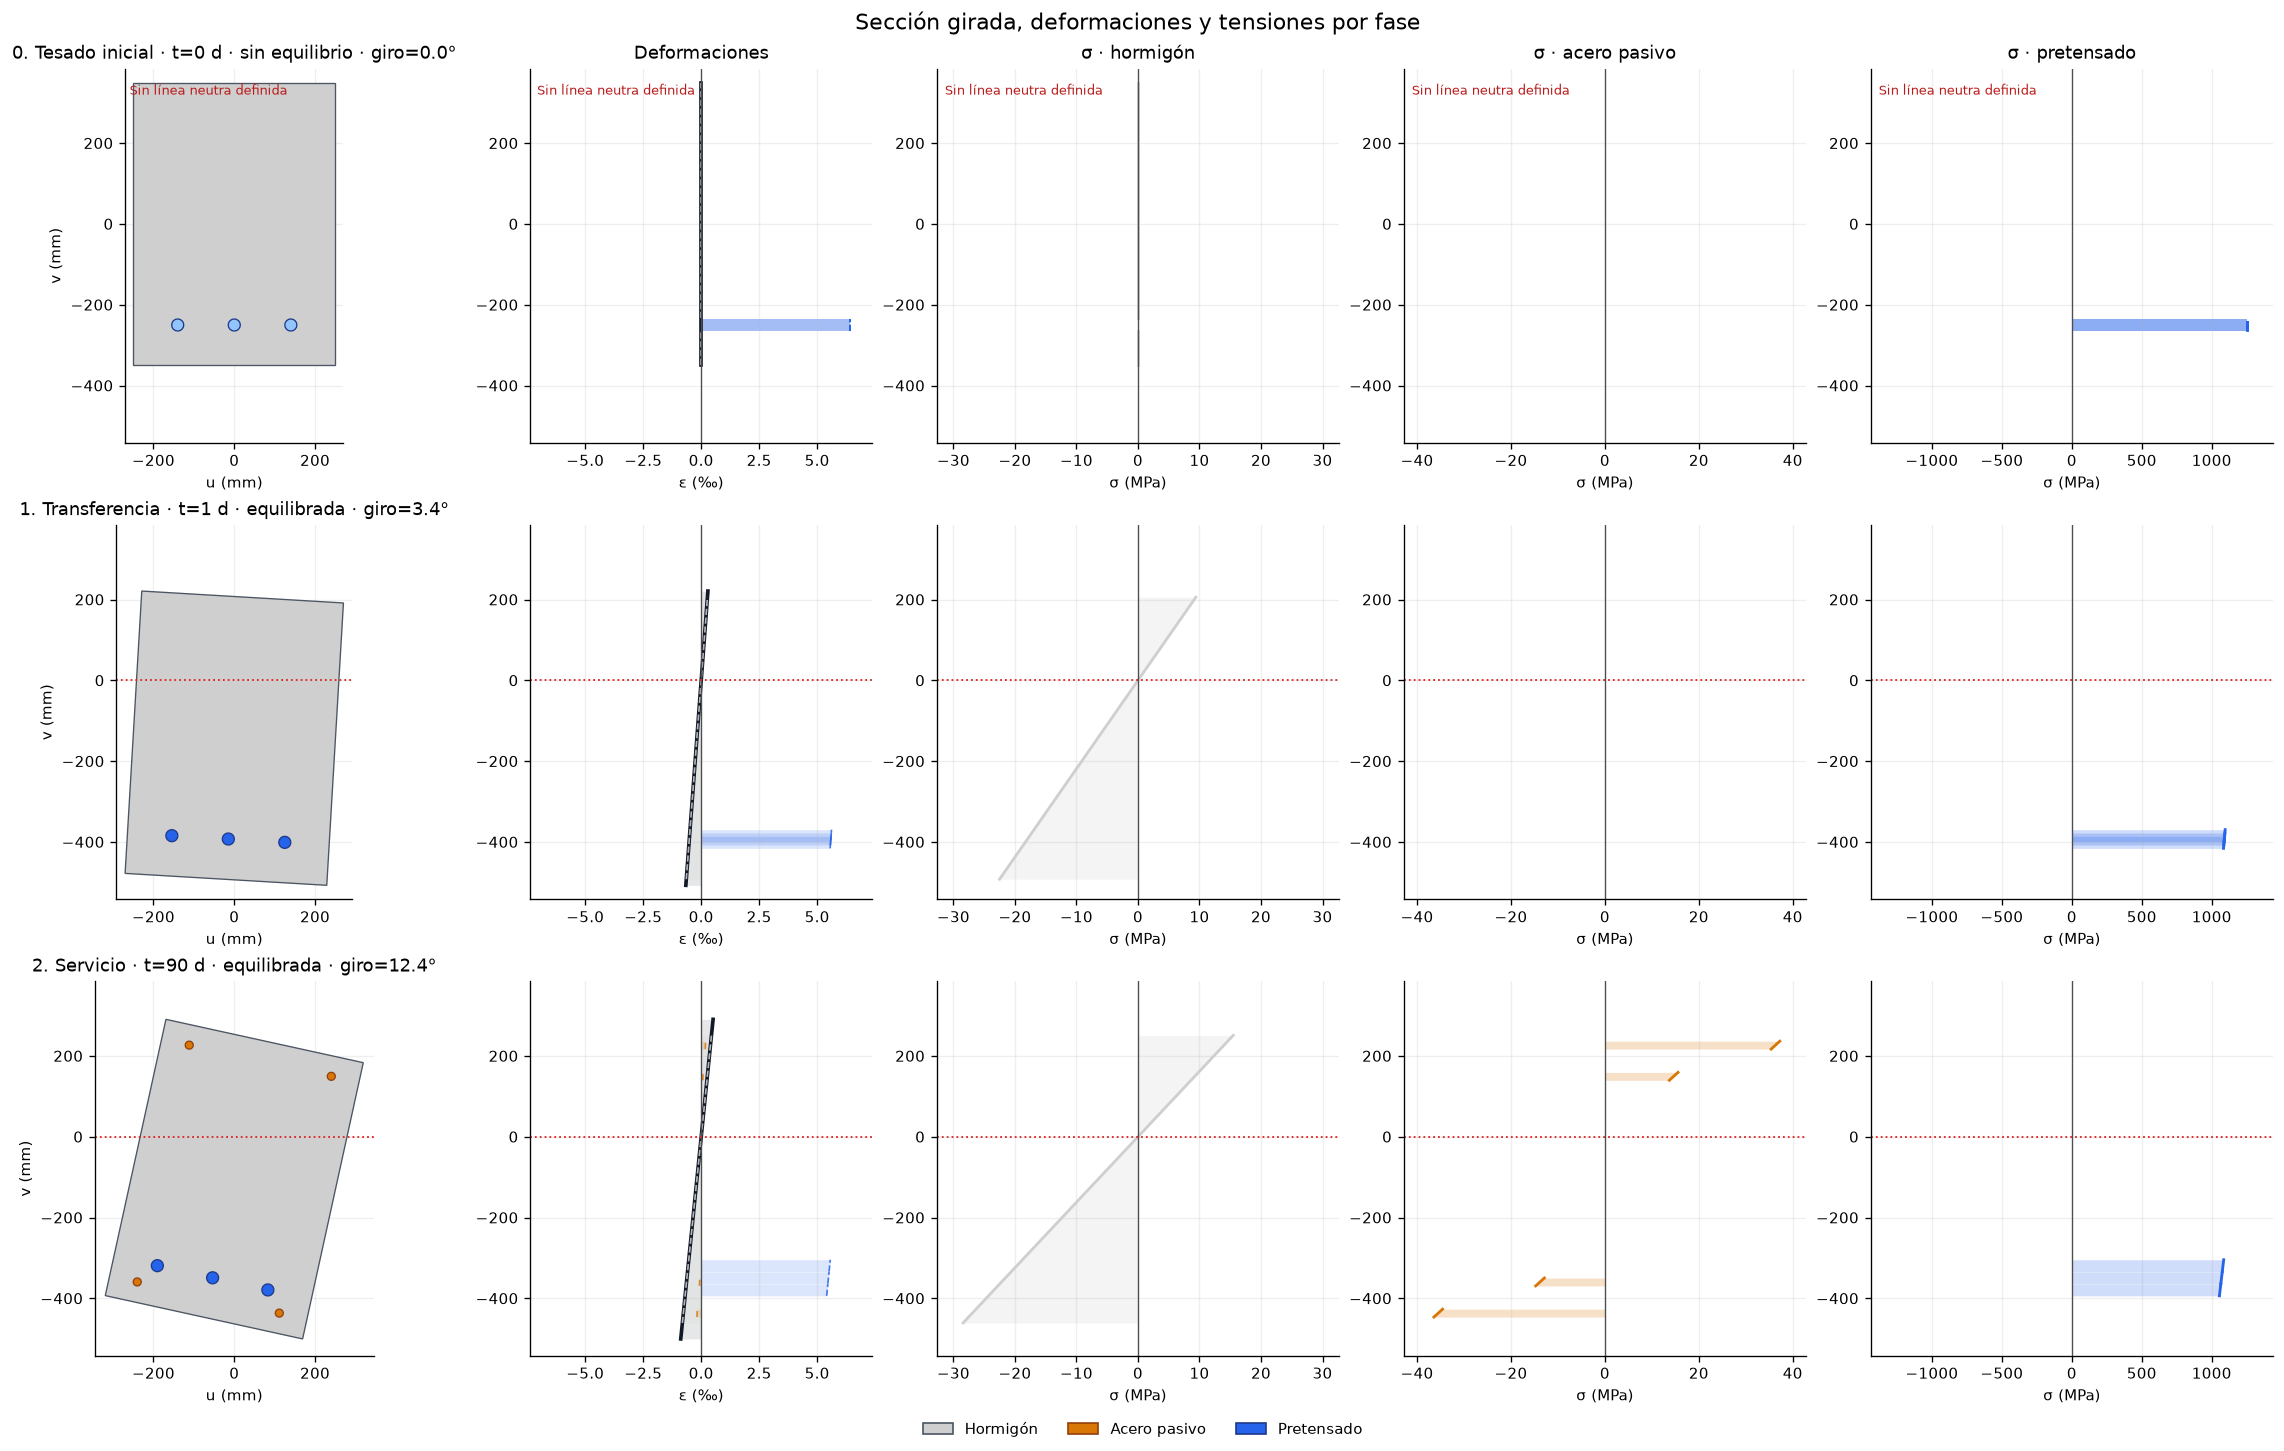

In [5]:
fig, ejes = plt.subplots(
    len(EVOLUCION.fases),
    5,
    figsize=(19, 4.0 * len(EVOLUCION.fases)),
    constrained_layout=True,
    gridspec_kw={"width_ratios": (1.15, 0.85, 1.0, 1.0, 1.0)},
)
for fila, fase in enumerate(EVOLUCION.fases):
    (
        ax_seccion,
        ax_eps,
        ax_sigma_hormigon,
        ax_sigma_pasivo,
        ax_sigma_activo,
    ) = ejes[fila]
    dibujar_seccion(ax_seccion, fase)
    dibujar_deformaciones(ax_eps, fase)
    dibujar_tensiones(
        ax_sigma_hormigon,
        fase,
        (TipoMaterialVista.HORMIGON,),
    )
    dibujar_tensiones(
        ax_sigma_pasivo,
        fase,
        (TipoMaterialVista.ACERO_ARMADURA,),
        etiquetar=fila == 0,
    )
    dibujar_tensiones(
        ax_sigma_activo,
        fase,
        (TipoMaterialVista.ACERO_PRETENSADO,),
        etiquetar=fila == 0,
    )

    cotas_u = [
        punto.u
        for componente in fase.componentes
        for punto in componente.geometria.exterior.puntos
    ]
    margen_u = 0.04 * (max(cotas_u) - min(cotas_u))
    ax_seccion.set_xlim(min(cotas_u) - margen_u, max(cotas_u) + margen_u)

    for ax in (
        ax_seccion,
        ax_eps,
        ax_sigma_hormigon,
        ax_sigma_pasivo,
        ax_sigma_activo,
    ):
        ax.set_ylim(Y_LIM)
        if fase.linea_neutra_definida:
            ax.axhline(0.0, color="#dc2626", linewidth=1.1, linestyle=":")
        else:
            ax.text(
                0.02,
                0.96,
                "Sin línea neutra definida",
                transform=ax.transAxes,
                va="top",
                fontsize=8,
                color="#b91c1c",
            )
    ax_eps.set_xlim(-EPS_LIM, EPS_LIM)
    ax_sigma_hormigon.set_xlim(-SIGMA_LIM_HORMIGON, SIGMA_LIM_HORMIGON)
    ax_sigma_pasivo.set_xlim(-SIGMA_LIM_PASIVO, SIGMA_LIM_PASIVO)
    ax_sigma_activo.set_xlim(-SIGMA_LIM_ACTIVO, SIGMA_LIM_ACTIVO)
    ax_seccion.set_ylabel("v (mm)")

    estado = "equilibrada" if fase.equilibrio_resuelto else "sin equilibrio"
    ax_seccion.set_title(
        f"{fase.indice}. {fase.nombre} · t={fase.tiempo_fin_dias:g} d · "
        f"{estado} · giro={math.degrees(fase.angulo_radianes):.1f}°"
    )
    if fila == 0:
        ax_eps.set_title("Deformaciones")
        ax_sigma_hormigon.set_title("σ · hormigón")
        ax_sigma_pasivo.set_title("σ · acero pasivo")
        ax_sigma_activo.set_title("σ · pretensado")

fig.legend(
    handles=[
        Patch(
            facecolor=COLORES[tipo],
            edgecolor=BORDES[tipo],
            label=ETIQUETAS[tipo],
        )
        for tipo in (
            TipoMaterialVista.HORMIGON,
            TipoMaterialVista.ACERO_ARMADURA,
            TipoMaterialVista.ACERO_PRETENSADO,
        )
    ],
    loc="outside lower center",
    ncol=3,
    frameon=False,
)
fig.suptitle(
    "Sección girada, deformaciones y tensiones por fase",
    fontsize=13,
)
plt.show()

## 7. Detalle de una fase: una escala por material

La escala se separa en tres gráficos de tensión: hormigón, acero pasivo y
pretensado. Así se aprecian las formas reales de cada material. La cota `v`, la
línea neutra y el relleno translúcido se mantienen en todos los paneles.

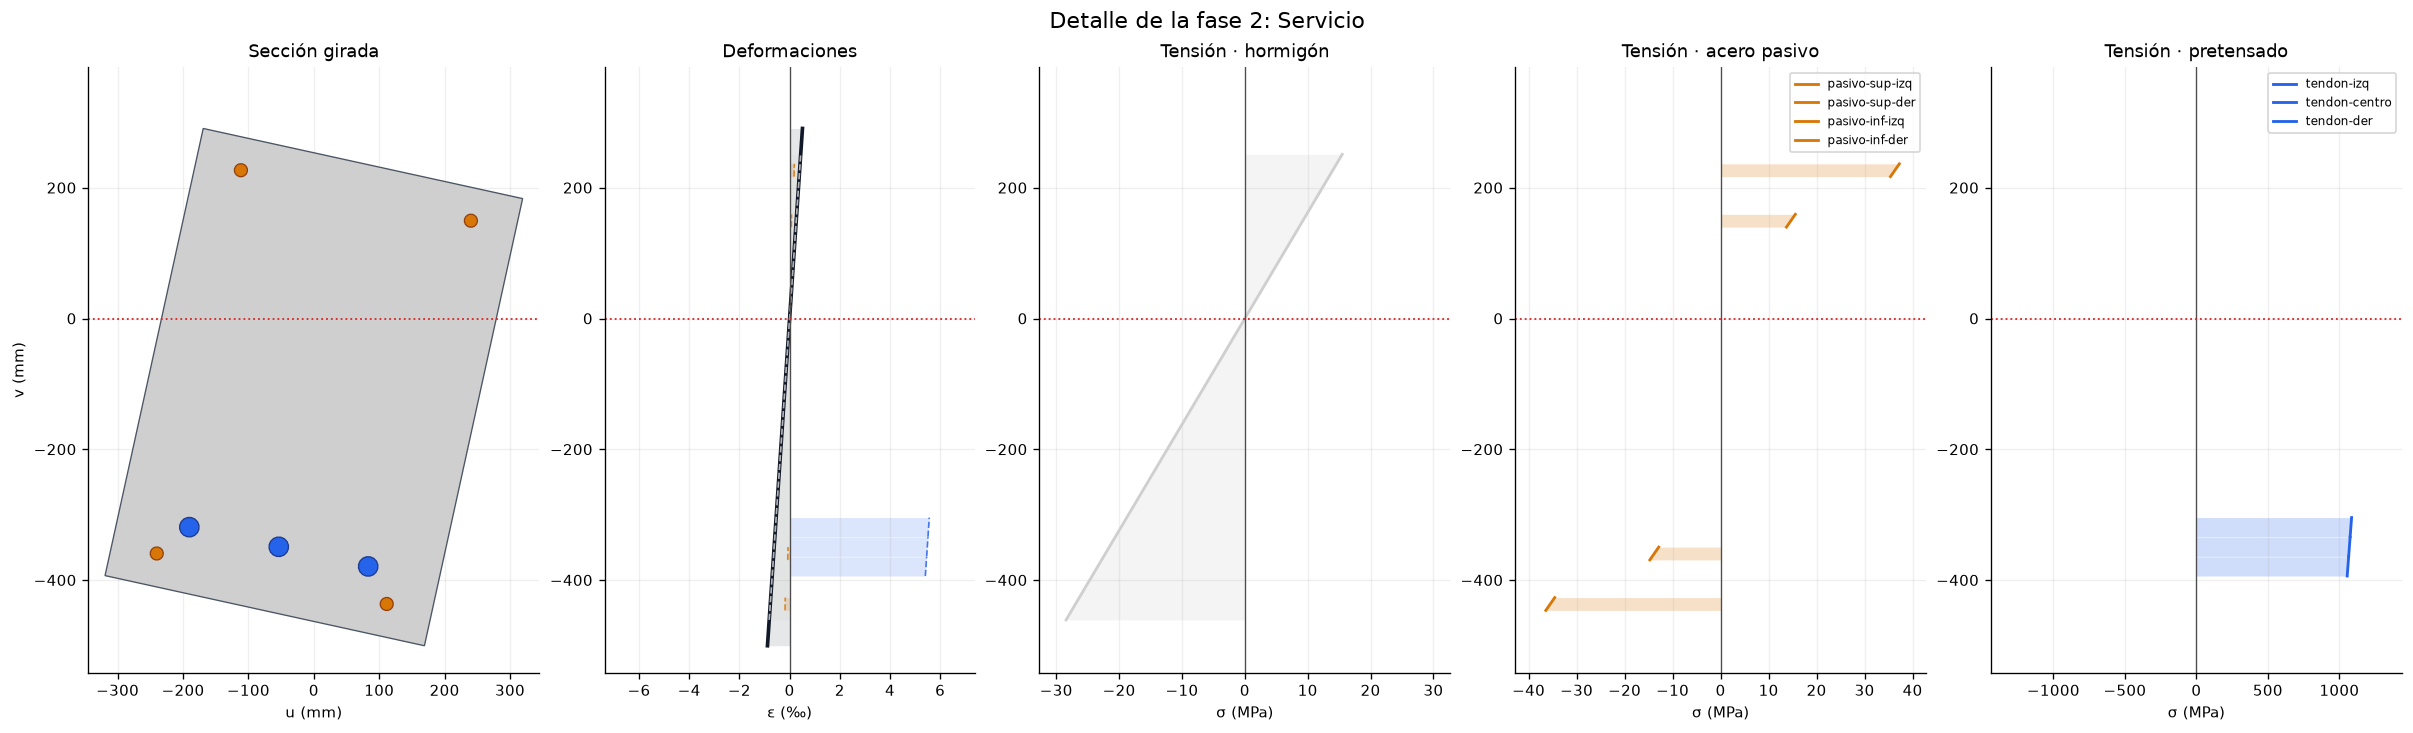

In [6]:
fase_detalle = EVOLUCION.fases[-1]
fig, ejes = plt.subplots(
    1,
    5,
    figsize=(20, 6),
    constrained_layout=True,
    gridspec_kw={"width_ratios": (1.1, 0.9, 1.0, 1.0, 1.0)},
)
(
    ax_seccion,
    ax_eps,
    ax_sigma_hormigon,
    ax_sigma_pasivo,
    ax_sigma_activo,
) = ejes
dibujar_seccion(ax_seccion, fase_detalle)
dibujar_deformaciones(ax_eps, fase_detalle)
dibujar_tensiones(
    ax_sigma_hormigon,
    fase_detalle,
    (TipoMaterialVista.HORMIGON,),
)
dibujar_tensiones(
    ax_sigma_pasivo,
    fase_detalle,
    (TipoMaterialVista.ACERO_ARMADURA,),
    etiquetar=True,
)
dibujar_tensiones(
    ax_sigma_activo,
    fase_detalle,
    (TipoMaterialVista.ACERO_PRETENSADO,),
    etiquetar=True,
)

cotas_u = [
    punto.u
    for componente in fase_detalle.componentes
    for punto in componente.geometria.exterior.puntos
]
margen_u = 0.04 * (max(cotas_u) - min(cotas_u))
ax_seccion.set_xlim(min(cotas_u) - margen_u, max(cotas_u) + margen_u)

for ax in ejes:
    ax.set_ylim(Y_LIM)
    if fase_detalle.linea_neutra_definida:
        ax.axhline(0.0, color="#dc2626", linewidth=1.1, linestyle=":")
ax_eps.set_xlim(-EPS_LIM, EPS_LIM)
ax_sigma_hormigon.set_xlim(-SIGMA_LIM_HORMIGON, SIGMA_LIM_HORMIGON)
ax_sigma_pasivo.set_xlim(-SIGMA_LIM_PASIVO, SIGMA_LIM_PASIVO)
ax_sigma_activo.set_xlim(-SIGMA_LIM_ACTIVO, SIGMA_LIM_ACTIVO)
ax_seccion.set_ylabel("v (mm)")
ax_seccion.set_title("Sección girada")
ax_eps.set_title("Deformaciones")
ax_sigma_hormigon.set_title("Tensión · hormigón")
ax_sigma_pasivo.set_title("Tensión · acero pasivo")
ax_sigma_activo.set_title("Tensión · pretensado")
ax_sigma_pasivo.legend(fontsize=7, loc="best")
ax_sigma_activo.legend(fontsize=7, loc="best")
fig.suptitle(
    f"Detalle de la fase {fase_detalle.indice}: {fase_detalle.nombre}",
    fontsize=13,
)
plt.show()

## 8. Comprobaciones

Las aserciones verifican las invariantes del contrato sin depender del dibujo:

- todas las fases están presentes y conservan su estado de equilibrio;
- la deformación común cumple $\varepsilon=\kappa v$;
- la línea neutra está en `v = 0` cuando está definida;
- los cordones tesados conservan su tensión antes de adherirse;
- el hormigón tiene huecos geométricos y su perfil se interrumpe;
- los aceros incorporados en la última fase aparecen en el DTO.

In [7]:
assert [fase.indice for fase in EVOLUCION.fases] == [0, 1, 2]
assert EVOLUCION.version_formato == 1
assert not EVOLUCION.fases[0].equilibrio_resuelto
assert EVOLUCION.fases[1].equilibrio_resuelto
assert EVOLUCION.fases[2].equilibrio_resuelto
assert not EVOLUCION.fases[0].linea_neutra_definida
assert EVOLUCION.fases[1].linea_neutra_definida
assert EVOLUCION.fases[2].linea_neutra_definida

for fase in EVOLUCION.fases:
    assert fase.limites.vertical.minimo <= fase.limites.vertical.maximo
    for muestra in fase.deformacion_comun:
        if fase.linea_neutra_definida:
            assert math.isclose(
                muestra.deformacion,
                fase.curvatura * muestra.v,
                rel_tol=1.0e-12,
                abs_tol=1.0e-15,
            )

fase_tesado = EVOLUCION.fases[0]
tendones_tesado = [
    componente
    for componente in fase_tesado.componentes
    if componente.tipo_material is TipoMaterialVista.ACERO_PRETENSADO
]
assert tendones_tesado
assert all(
    componente.adherencia is AdherenciaVista.ENFUNDADO
    for componente in tendones_tesado
)
assert all(
    math.isclose(muestra.tension, 1_250.0, rel_tol=1.0e-12)
    for componente in tendones_tesado
    for tramo in componente.perfil.tramos
    for muestra in tramo.muestras
)

hormigon = next(
    componente
    for componente in EVOLUCION.fases[2].componentes
    if componente.tipo_material is TipoMaterialVista.HORMIGON
)
pasivos = [
    componente
    for componente in EVOLUCION.fases[2].componentes
    if componente.tipo_material is TipoMaterialVista.ACERO_ARMADURA
]
assert len(hormigon.geometria.huecos) == 7
assert len(pasivos) == 4
assert all(componente.perfil.tramos for componente in pasivos)
print("Todas las invariantes del modelo de visualización se cumplen.")

Todas las invariantes del modelo de visualización se cumplen.


## 9. Alcance y siguientes pasos

Esta primera versión demuestra el contrato y el dibujo. Limitaciones conocidas:

- el perfil se extrae en la vertical del centroide de cada componente; en
  flexión biaxial la tensión también varía en dirección `u`, por lo que más
  adelante se añadirán envolventes o mapas 2D;
- la evolución es discreta entre fases: no interpola dentro de una fase;
- el DTO aún no incluye un serializador JSON versionado;
- la UI PySide, la reproducción animada y la exportación SVG/PNG quedan como
  adaptadores posteriores sobre el mismo contrato.

Para ejecutar el cuaderno:

```powershell
.venv\Scripts\activate
pip install -e ".[dev,notebooks]"
jupyter nbconvert --execute --to notebook --inplace notebooks\ejemplo_2_visualizacion_tensiones.ipynb
```